# [Lab Session 3](fourier.ipynb)


In [114]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


<function matplotlib.pyplot.show(close=None, block=None)>

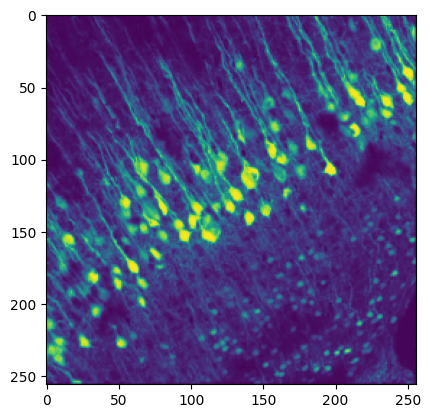

In [115]:
cell_img = plt.imread('data/cells.png')
img_resized = resize(cell_img, (256,256))

plt.figure()
plt.imshow(img_resized)
plt.show

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [116]:
#FFT
cell_ft = np.fft.fft2(img_resized)
cell_ft.dtype

dtype('complex128')

**[Task 1 (c).]()** Extract the phase and amplitude and display them.


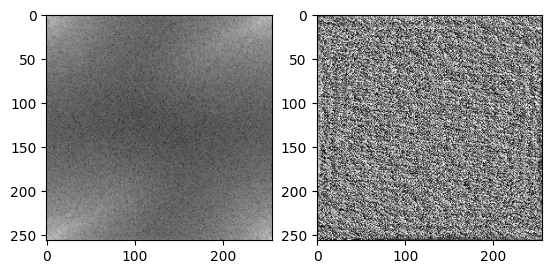

In [117]:
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


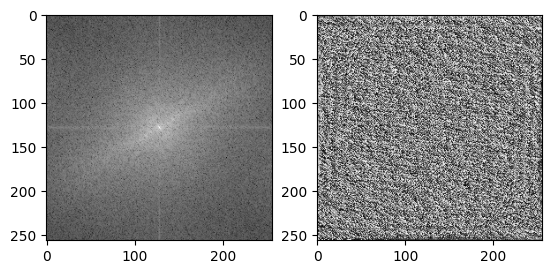

In [118]:
cell_shifted = np.fft.fftshift(cell_ft)

amplitude_sh = np.abs(cell_shifted)
phase_sh = np.angle(cell_shifted)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_sh), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


<function matplotlib.pyplot.show(close=None, block=None)>

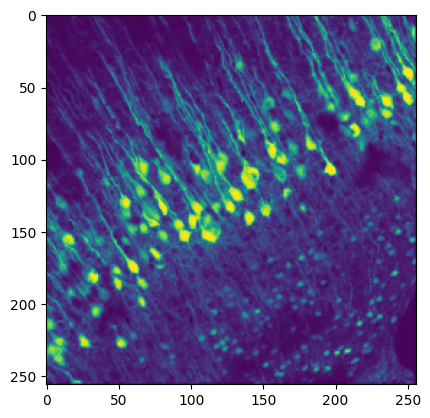

In [119]:
#IFFT
cell_shift_rev = np.fft.ifftshift(cell_shifted) 
cell_restored = np.fft.ifft2(cell_shift_rev)
cell_restored.dtype

plt.figure()
plt.imshow(cell_restored.real)
plt.show

---


**[Task 2 (a).]()** Load the brain MR image.


In [120]:
mri = plt.imread('data/brain_mri.png')

**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


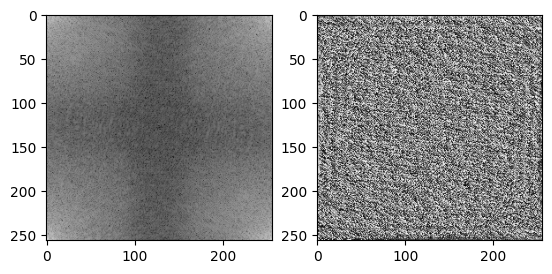

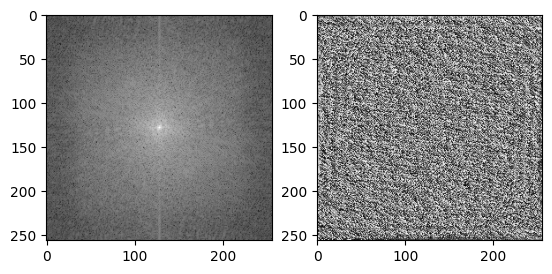

In [121]:
#FFT
mri_ft = np.fft.fft2(mri)
mri_ft.dtype

#shift
amplitude_mri = np.abs(mri_ft)
phase_mri = np.angle(mri_ft)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_mri), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')



mri_shifted = np.fft.fftshift(mri_ft)

amplitude_mri_sh = np.abs(mri_shifted)
phase_mri_sh = np.angle(mri_shifted)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_mri_sh), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

In [122]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


<function matplotlib.pyplot.show(close=None, block=None)>

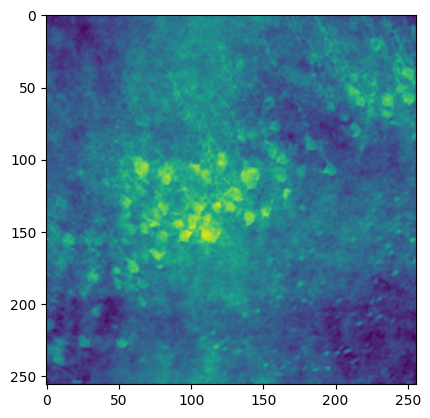

In [123]:
amplitude_mri_sh = np.abs(mri_shifted)
phase_sh = np.angle(cell_shifted)

merged_sh_1 = amplitude_mri_sh * np.exp(1j * phase_sh)

#IFFT
merged_sh_1_rev = np.fft.ifftshift(merged_sh_1) 
merged_1_restored = np.fft.ifft2(merged_sh_1_rev)
merged_1_restored.dtype

plt.figure()
plt.imshow(merged_1_restored.real)
plt.show

**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


<function matplotlib.pyplot.show(close=None, block=None)>

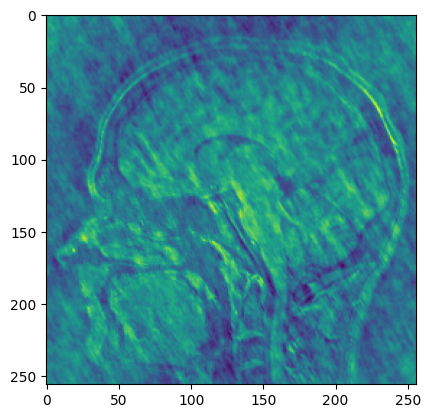

In [124]:
amplitude_sh = np.abs(cell_shifted)
phase_mri_sh = np.angle(mri_shifted)

merged_sh_2 = amplitude_sh * np.exp(1j * phase_mri_sh)

#IFFT
merged_sh_2_rev = np.fft.ifftshift(merged_sh_2) 
merged_2_restored = np.fft.ifft2(merged_sh_2_rev)
merged_2_restored.dtype

plt.figure()
plt.imshow(merged_2_restored.real)
plt.show

# die phase hat mehr informationen!

---


**[Task 3 (a).]()** Create a lowpass filter mask.


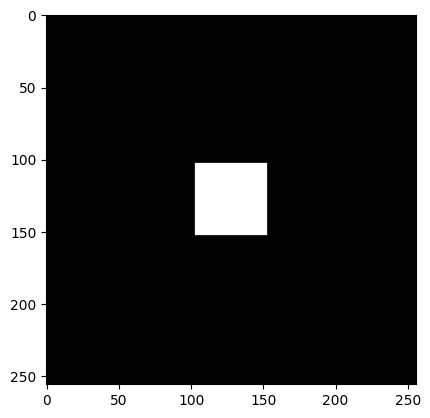

In [125]:
lp_mask = np.zeros((256,256))
filter_window_size = 10

# wenn man nur / macht, ist es float
# wenn man // macht, ist es int
center = 256 // 2             
half_size = filter_window_size // 2

# von center - half_size bis center + half_size
lp_mask[center - half_size : center + half_size, center - half_size : center + half_size] = 1

plt.imshow(mask, cmap='gray')
plt.show()

**[Task 3 (b).]()** Create a highpass filter maks.


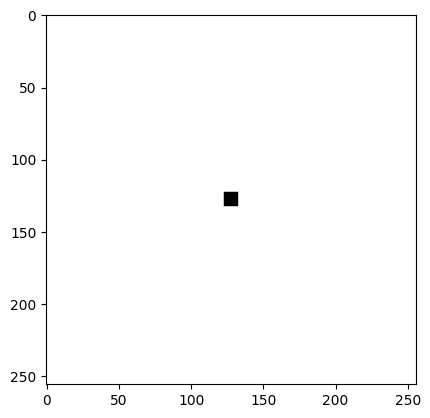

In [126]:
hp_mask = 1 - lp_mask

plt.imshow(hp_mask, cmap='gray')
plt.show()

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


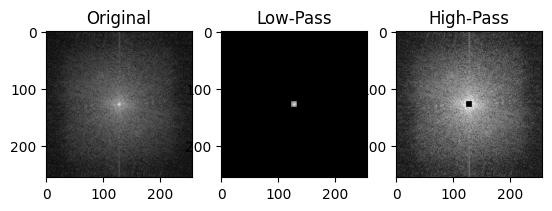

In [127]:
amplitude_mri_sh = np.abs(mri_shifted)
applied_lp = lp_mask * amplitude_mri_sh
applied_hp = hp_mask * amplitude__mri_sh

#Original
plt.subplot(1, 3, 1)
plt.imshow(np.log1p(amplitude_mri_sh), cmap='gray')
plt.title("Original")

#Low-Pass
plt.subplot(1, 3, 2)
plt.imshow(np.log1p(applied_lp), cmap='gray')
plt.title("Low-Pass")

#High-Pas
plt.subplot(1, 3, 3)
plt.imshow(np.log1p(applied_hp), cmap='gray')
plt.title("High-Pass")

plt.show()

**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


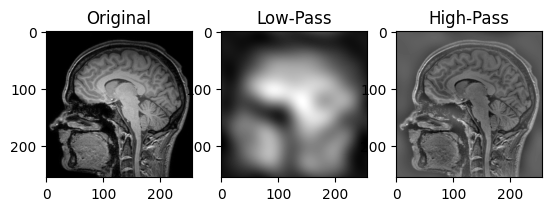

In [ ]:
# Phase of the brain image
phase_mri_sh = np.angle(mri_shifted)

# mergen
complex_lp_sh = applied_lp * np.exp(1j * phase_mri_sh)
complex_hp_sh = applied_hp * np.exp(1j * phase_mri_sh)

#shift reverse und IFFT
complex_lp_rev = np.fft.ifftshift(complex_lp_sh) 
complex_lp_restored = np.fft.ifft2(complex_lp_rev)

complex_hp_rev = np.fft.ifftshift(complex_hp_sh) 
complex_hp_restored = np.fft.ifft2(complex_hp_rev)

# show
#Original
plt.subplot(1, 3, 1)
plt.imshow(mri, cmap='gray')
plt.title("Original")

#Low-Pass
plt.subplot(1, 3, 2)
plt.imshow(complex_lp_restored.real, cmap='gray')
plt.title("Low-Pass")

#High-Pas
plt.subplot(1, 3, 3)
plt.imshow(complex_hp_restored.real, cmap='gray')
plt.title("High-Pass")

plt.show()

#je kleiner der filter wird, desto besser wird das high-pass bild und andersrum


---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [138]:
def twoD_DFT(img):
    M, N = img.shape
    dft = np.zeros((M, N), dtype=complex)
    
    # Koordinaten-Gitter für x und y erstellen
    x = np.arange(M).reshape((M, 1))
    y = np.arange(N).reshape((1, N))
    
    for u in range(M):
        for v in range(N):
            # Berechnet die komplette Doppelsumme für (u, v) auf einen Schlag
            exponent = -2j * np.pi * ((u * x) / M + (v * y) / N)
            dft[u, v] = np.sum(img * np.exp(exponent)) / (M * N)
            
    return dft



**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


In [ ]:
def twoD_DFT(img):
    M, N = img.shape
    dft = np.zeros((M, N), dtype=complex)
    
    # Koordinaten-Gitter für x und y erstellen
    x = np.arange(M).reshape((M, 1))
    y = np.arange(N).reshape((1, N))
    
    for u in range(M):
        for v in range(N):
            # Berechnet die komplette Doppelsumme für (u, v) auf einen Schlag
            exponent = -2j * np.pi * ((u * x) / M + (v * y) / N)
            dft[u, v] = np.sum(img * np.exp(exponent)) / (M * N)
            
    return dft
    
# in brain image ausprobieren
DFT_mri = twoD_DFT(mri)
amplitude = np.abs(DFT_mri)
phase = np.angle(DFT_mri)



Due to high computational costs, we need to resize the image.


In [129]:
test_img = resize(brain_img, (40, 40))
plt.imshow(test_img, 'gray')

NameError: name 'brain_img' is not defined

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


**[Task 4 (f).]()** Round the arrays and compare them again.


**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)
